| Интервал ||               xi ||        W||            f(xi) теоретическая|
----------
|Интервал:    [32, 33) || xi:   32.50 || W:   0.0556 ||f(x):   0.0387 |
|Интервал:    [33, 34) || xi:   33.50 || W:   0.0833 ||f(x):   0.1130 |
|Интервал:    [34, 35) || xi:   34.50 || W:   0.2778 ||f(x):   0.2141 |
|Интервал:    [35, 36) || xi:   35.50 || W:   0.2222 ||f(x):   0.2627 |
|Интервал:    [36, 37) || xi:   36.50 || W:   0.2222 ||f(x):   0.2090 |
|Интервал:    [37, 38) || xi:   37.50 || W:   0.0556 ||f(x):   0.1077 |
|Интервал:    [38, 39) || xi:   38.50 || W:   0.0833 ||f(x):   0.0360 |
Квантиль распределения Стьюдента: 1.9996
Точечная оценка: 36.9355
Интервальное СКО: 14.0897
Точность: 3.5781
Доверительный интервал для оценк. мат. ожид. --> ( 33.3574 < a < 40.5136 )


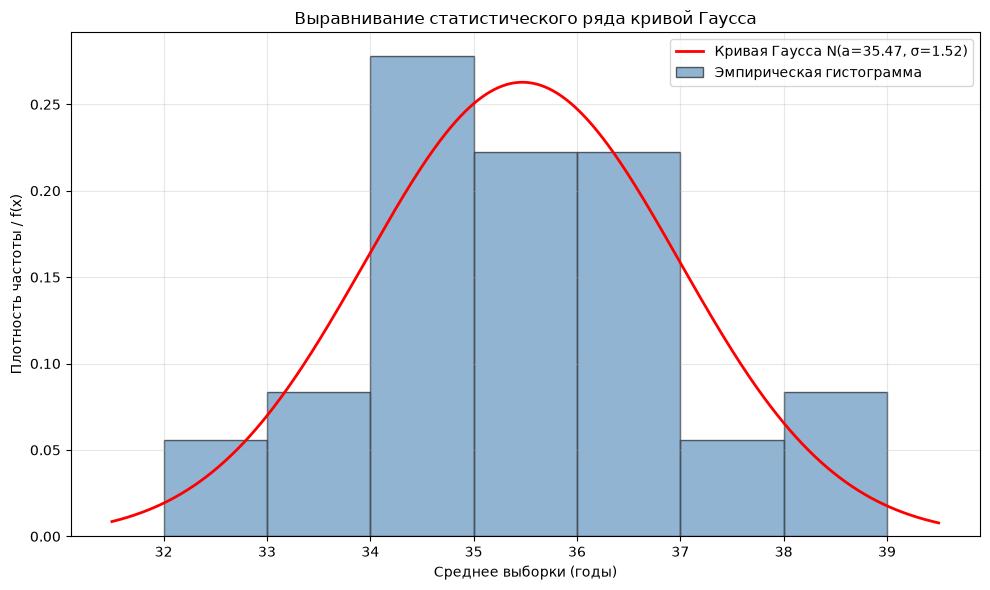

In [ ]:
#Библиотеки
from math import ceil, sqrt
from pathlib import Path # Библиотека для работы с файлами и их адресами
from scipy.stats import t
from scipy.stats import norm #
import math # Библиотка для математический действий
import matplotlib.pyplot as plt # библиотека для рисования графико и диаграмм в в питоне.
from random import randint

# Вычисление объема
def calculate_n (d):# Высчитываем объем группы для одной выборки
   y = 0.95 # надежность из условия из условия
   b = 3 # точность оценки математического ожидания из условия
   f_t = (y+1) / 2
   t = norm.ppf(f_t) 
   n = t**2 * d**2 / b**2
   n = int(math.ceil(n))  # округляем в большую сторону чтобы n было целым числом
   return n

# Создание групп и нахождение средних
def lets_make_a_groops (numbers, n, N): # создаем 36 групп по полученному n (объему выборки) из функции calculate_n
    k = 36 # количество групп из условия
    all_selections = [] # список со списками выборок, 36 штук
    mid = [] # среднии для каждой выборки
    for selection in range(k):
        one = [] # одна выборка
        sum_ = 0 # сумма для подсчета среднего
        for num in range(n):
            i = randint(0, N - 1) # выбор случайных чисел по условию репрезитативности выборки
            one.append(numbers[i]) # добавление элемента выборку
            sum_ += numbers[i]
        mid.append(sum_ / len(one)) # подсчет средней
        all_selections.append(one) # добавление одной выборки в список выборок
    return all_selections, mid # возвращает картеж со списком списокв выборок и списком средних


# Функции которые вычисляют точечные оценки
def midle_calc (interval): # функция для расчета середины интервала
    midle = (interval[0] + interval[1]) / 2
    return midle

def calculate_a (interval, n_i): # функция для расчета средней интервального ряда
    return midle_calc(interval) * n_i

def calculate_d (a, interval, n_i): # функция для расчета ско интервального ряда
    return n_i * ( midle_calc(interval) - a)**2

def f_x_calculate (x, a, d):# расчет высот теор. кривых для каждого x по формуле Гауса
    f_x = ( 1 / (d * sqrt(2 * math.pi)) * math.e**(-(x - a)**2 / (2 * d**2)))
    return f_x

def gistogram_building (intervals, chastots, a, d, N):
    int_mids = [midle_calc(interval) for interval in intervals]
    fig, ax = plt.subplots(figsize=(10, 6))
    # Гистограмма по относительным частотам
    w = [n / N for n in chastots]
    ax.bar(int_mids, w, width=1.0,
           color='steelblue', edgecolor='black', alpha=0.6,
           label="Эмпирическая гистограмма")
    # Кривая Гаусса
    x_min = min(int_mids) - 1
    x_max = max(int_mids) + 1
    xs = [x_min + i * 0.01 for i in range(int((x_max - x_min) * 100) + 1)]
    ys = [f_x_calculate(x, a, d) for x in xs]
    ax.plot(xs, ys, color='red', linewidth=2,
            label=f"Кривая Гаусса N(a={a:.2f}, σ={d:.2f})")
    ax.set_title("Выравнивание статистического ряда кривой Гаусса")
    ax.set_xlabel("Среднее выборки (годы)")
    ax.set_ylabel("Плотность частоты / f(x)")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()


# Создание интервалов и связанные с ними операции
def inteval_raw_building (mid, N): # функция для построения и выведения интервального ряда
    sn = sorted(mid)
    left = math.floor(min(mid)) #левая граница – округленное вниз минимальное значение выборочной средней
    right = math.ceil(max(mid)) # правая граница – округленное вверх максимальное значение выборочной средней
    intervals = [] # список интервалов
    for edge in range(left, right):
        one = [edge, edge + 1] # создание одного интервала
        intervals.append(one) # добавление интервала
    chastots = [] # список частот
    a = 0 
    for interval in intervals: # вычисление частот попадания в интервал
        k = 0
        for val in sn:
            if sn.index(val) == len(sn) - 1:
                if interval[0] <= val <= interval[1]:
                    k += 1
            else:
                 if interval[0] <= val < interval[1]:
                    k += 1
        chastots.append(k)
        a += calculate_a(interval, k)
    w = [(i / N) for i in chastots] # h = 1, значит плотность = nᵢ / N = w.
    a = a / N # Находим среднее 
    k = 0
    D = 0
    for interval in intervals: # находим СКО
        D += calculate_d(a, interval, chastots[k])
        k+=1
    D = D / N
    d = sqrt(D)
    f_x = [f_x_calculate((letht + right) / 2, a, d) for letht, right in intervals]
    
    # Вывод интервала
    print(f"| {'Интервал':>6} || {'xi':>16} || {'W':>8}|| {'f(xi) теоретическая':>30}|")
    k = 0
    print("-" * 10)
    for interval in intervals: # вывод интервалов, частот, относительных частот
        x_i = (interval[0] + interval[1]) / 2
        interv = f"[{interval[0]}, {interval[1]})"
        print(f"|Интервал:{interv:>12} || xi: {x_i:>7.2f} || W: {w[k]:>8.4f} ||f(x): {f_x[k]:>8.4f} |")
        k += 1
    return intervals, chastots, a, d, N

# Функции вычисления для доверительного интервала мат. ожидания
def x_calculating (vyborka, n): # Фунцкция высчитывания средней
    sn = sorted(set(vyborka))
    x = sum(v * vyborka.count(v) for v in sn) / n
    return x 
def d_calculating (vyborka, k, x): # функция  высчитывания исправленного СКО
    sn = sorted(set(vyborka))
    D = sum((xi - x)**2 * vyborka.count(xi) for xi in sn) / k
    return sqrt(D)
def cvantil_student_calculating (k): # функция  высчитывания квантиля Стьюдента
    gamma = 0.95
    cvantil  = t.ppf((1 + gamma) / 2, df= k) # обратная функция которая возвращает квантиль Стюдента
    return cvantil
def dov_raw_calculating (t, x, s, n): # функция вычисления границ доверительного интервала
    delta = t * s / sqrt(n)
    left = x - delta
    right = x + delta
    return left, right, delta

# Построение доверительного интервала
def dov_interval_builder (vyborka):
    n = len(vyborka) # объем выборки
    k = n - 1 # число степеней свободы
    t = cvantil_student_calculating(k)
    x = x_calculating(vyborka, n)
    s = d_calculating(vyborka, k, x)
    left, right, delta = dov_raw_calculating(t, x, s, n)
    print(f"Квантиль распределения Стьюдента: {t:.4f}")
    print(f"Точечная оценка: {x:.4f}")
    print(f"Интервальное СКО: {s:.4f}")
    print(f"Точность: {delta:.4f}")
    print(f"Доверительный интервал для оценк. мат. ожид. --> ( {left:.4f} < a < {right:.4f} )")

fp = Path("./Москва_2021.txt") 
if fp.exists():
    with open(fp, "r", encoding="utf-8") as f: # Открыть и прочитать файл, на любом языке с переменной файла f
        numbers = sorted([int(line.strip()) for line in f if line.strip()])
    sn = sorted(set(numbers))
    N = 0 # Сумма частот
    x_midl = 0 # Среднее +
    for i in sn:
        n = numbers.count(i) # кол. элемента
        x_midl += i * n # высчитываем сумму среднего, но пока без деления на сумму частот
        N+= n
    x_midl /= N
    D = 0
    for i in sn:
        D += (i - x_midl)**2 * numbers.count(i)
    D = D / N # Дисперсия
    d = math.sqrt(D) # среднее квадратичное отклонение
    n = calculate_n(d) # высчитываем объем
    all_selections, mid = lets_make_a_groops(numbers, n, N) # получаем список списков групп + список средних
    intervals, chastots, a, d, N = inteval_raw_building(mid, len(mid)) # строим интервальный ряд
    dov_interval_builder(all_selections[0])
    gistogram_building(intervals, chastots, a, d, N)
else:
    print("Скачайте или создайте файл Москва_2021.txt")